# Week 4 — Predictive Modelling and Optimization in Logistics

**Prediction problem:** Predict the number of days from purchase to customer delivery for orders that are eventually delivered. This is a regression task.

**Business use:** help operations teams identify orders likely to take longer, plan capacity and improve customer communication. Predictions are decision-support estimates, not guaranteed delivery promises.

**Important:** only information plausibly available at purchase is used as an input. Actual delivery dates, delivery delay, final status and reviews are excluded to prevent target leakage.

Install: `python -m pip install pandas numpy scikit-learn matplotlib seaborn joblib`. Run Week 2 first.

In [1]:
!python -m pip install --upgrade pip


In [3]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, joblib
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
print("scikit-learn:",sklearn.__version__)
def find_root():
    for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]:
        if (p/"data"/"processed"/"orders_preprocessed.csv").exists(): return p
    raise FileNotFoundError("Run Week 2 first.")
ROOT=find_root(); PROC=ROOT/"data"/"processed"; REPORTS=ROOT/"reports"
REPORTS.mkdir(exist_ok=True)
orders=pd.read_csv(PROC/"orders_preprocessed.csv")
items=pd.read_csv(PROC/"logistics_items_analysis.csv")
for c in ["order_purchase_timestamp","order_delivered_customer_date"]:
    orders[c]=pd.to_datetime(orders[c],errors="coerce")

scikit-learn: 1.9.1


## 1. Define the target and construct features

Target: actual delivery days = customer delivery timestamp minus purchase timestamp.

We aggregate item-level records to one row per order. Predictors include purchase month, weekday and hour, customer/seller state, item count, item price and freight. These are available at or near purchase in principle.

**Leakage examples to exclude:** actual delivery timestamp, actual delivery duration, delay days, final order status, review score and any post-delivery event. Including these would make the model appear accurate while making it unusable at prediction time.

In [4]:
customers=pd.read_csv(ROOT/"data"/"raw"/"olist_customers_dataset.csv")
cust=customers[["customer_id","customer_state"]].drop_duplicates("customer_id")
base=orders.merge(cust,on="customer_id",how="left",validate="many_to_one")
for c in ["price","freight_value"]: items[c]=pd.to_numeric(items[c],errors="coerce")
item_features=items.groupby("order_id").agg(
 item_count=("order_item_id","count"),
 total_price=("price","sum"),total_freight=("freight_value","sum"),
 mean_price=("price","mean"),
 seller_state=("seller_state",lambda s:s.mode().iloc[0] if not s.mode().empty else np.nan)
).reset_index()
data=base.merge(item_features,on="order_id",how="left",validate="one_to_one")
data["target_days"]=(data.order_delivered_customer_date-data.order_purchase_timestamp).dt.total_seconds()/86400
data=data[data.target_days.notna() & (data.target_days>=0) & data.order_purchase_timestamp.notna()].copy()
data["month"]=data.order_purchase_timestamp.dt.month
data["weekday"]=data.order_purchase_timestamp.dt.dayofweek
data["hour"]=data.order_purchase_timestamp.dt.hour
data["year"]=data.order_purchase_timestamp.dt.year
data["weekend"]=(data.weekday>=5).astype(int)
print("Eligible labelled orders:",len(data)); display(data.head())

Eligible labelled orders: 96476


C:\Users\SenthamizhSelvan\AppData\Local\Temp\ipykernel_21244\1873499221.py:15: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["weekday"]=data.order_purchase_timestamp.dt.dayofweek


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_timestamp_missing,actual_delivery_days,...,total_price,total_freight,mean_price,seller_state,target_days,month,weekday,hour,year,weekend
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,8.436574,...,29.99,8.72,29.99,SP,8.436574,10,0,10,2017,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,13.782037,...,118.70,22.76,118.70,SP,13.782037,7,1,20,2018,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,9.394213,...,159.90,19.22,159.90,SP,9.394213,8,2,8,2018,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0,13.208750,...,45.00,27.20,45.00,MG,13.208750,11,5,19,2017,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0,2.873877,...,19.90,8.72,19.90,SP,2.873877,2,1,21,2018,0


## 2. Explore the target and define metrics

MAE is the average absolute error in days and is easy to communicate. RMSE penalizes large errors more heavily. R-squared compares model performance with a mean prediction baseline; a negative test R² is possible and indicates poor generalization.

MAE is the main business metric because it answers: “On average, how many days away are predictions from the actual delivery time?”

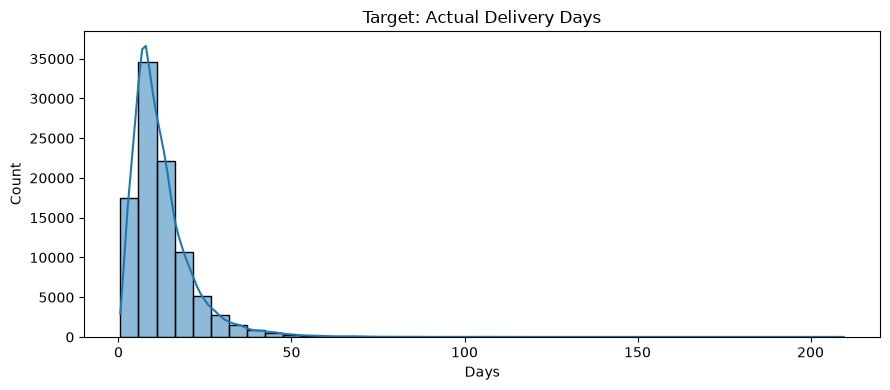

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
50%         10.217755
90%         23.097604
95%         29.276016
max        209.628611
Name: target_days, dtype: float64

In [5]:
plt.figure(figsize=(9,4)); sns.histplot(data.target_days,bins=40,kde=True)
plt.title("Target: Actual Delivery Days"); plt.xlabel("Days"); plt.tight_layout()
plt.savefig(REPORTS/"week4_target_distribution.png",dpi=160); plt.show()
display(data.target_days.describe(percentiles=[.5,.9,.95]))

## 3. Chronological train/test split

We sort orders by purchase time and use the earliest 80% for training and the latest 20% for testing. This reflects the real use case: train on the past, estimate future orders. The test set is kept untouched during model selection.

In [6]:
data=data.sort_values("order_purchase_timestamp").reset_index(drop=True)
cut=int(len(data)*.8); train=data.iloc[:cut].copy(); test=data.iloc[cut:].copy()
print("Train:",train.order_purchase_timestamp.min(),"to",train.order_purchase_timestamp.max())
print("Test:",test.order_purchase_timestamp.min(),"to",test.order_purchase_timestamp.max())
num=["month","weekday","hour","year","weekend","item_count","total_price","total_freight","mean_price"]
cat=["customer_state","seller_state"]; features=num+cat
X_train,y_train=train[features],train.target_days
X_test,y_test=test[features],test.target_days

Train: 2016-09-15 12:16:38 to 2018-05-26 16:54:05
Test: 2018-05-26 17:57:44 to 2018-08-29 15:00:37


## 4. Preprocessing pipeline and baseline

Numeric fields are median-imputed and standardized. Categorical fields are filled with the most frequent category and one-hot encoded. Putting preprocessing inside a Pipeline ensures that transformations are learned from training data only.

A DummyRegressor predicts the training median for every order. The more complex model must beat this baseline on the held-out period to demonstrate value.

In [7]:
numeric_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
category_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
 ("onehot",OneHotEncoder(handle_unknown="ignore",min_frequency=10))])
prep=ColumnTransformer([("num",numeric_pipe,num),("cat",category_pipe,cat)])
baseline=Pipeline([("prep",prep),("model",DummyRegressor(strategy="median"))])
baseline.fit(X_train,y_train); pred_base=baseline.predict(X_test)

## 5. Model selection and time-aware tuning

A Random Forest is an ensemble of decision trees. It can learn non-linear relationships and interactions between calendar, geography and order characteristics. We tune a small set of complexity parameters with TimeSeriesSplit using only the training period. The final test period is not used in tuning.

In [8]:
rf=Pipeline([("prep",prep),("model",RandomForestRegressor(
 n_estimators=200,min_samples_leaf=4,max_features=.8,random_state=42,n_jobs=-1))])
grid={"model__max_depth":[None,12],"model__min_samples_leaf":[4,10],
      "model__max_features":[.7,1.0]}
cv=TimeSeriesSplit(n_splits=3)
search=GridSearchCV(rf,grid,cv=cv,scoring="neg_mean_absolute_error",n_jobs=-1,verbose=1)
search.fit(X_train,y_train); model=search.best_estimator_
print("Best settings:",search.best_params_,"CV MAE:",-search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best settings: {'model__max_depth': 12, 'model__max_features': 0.7, 'model__min_samples_leaf': 10} CV MAE: 6.330360587930074


## 6. Evaluate on the untouched test period

Compare the tuned model with the baseline. Do not call the model successful unless it improves on the baseline and the errors are acceptable for the business use. Always report units in days.

In [9]:
def scores(y,p,name):
 return {"model":name,"MAE_days":mean_absolute_error(y,p),
         "RMSE_days":np.sqrt(mean_squared_error(y,p)),"R2":r2_score(y,p)}
pred=model.predict(X_test)
results=pd.DataFrame([scores(y_test,pred_base,"Median baseline"),
                      scores(y_test,pred,"Tuned Random Forest")])
display(results); results.to_csv(REPORTS/"week4_model_metrics.csv",index=False)

,model,MAE_days,RMSE_days,R2
0,Median baseline,4.962445,6.380479,-0.169492
1,Tuned Random Forest,4.510067,5.908555,-0.002890


## 7. Diagnostic plots

Predicted-versus-actual values should lie near the diagonal. Residuals are `actual - predicted`; a residual pattern may reveal systematic underprediction, overprediction or larger errors for long deliveries.

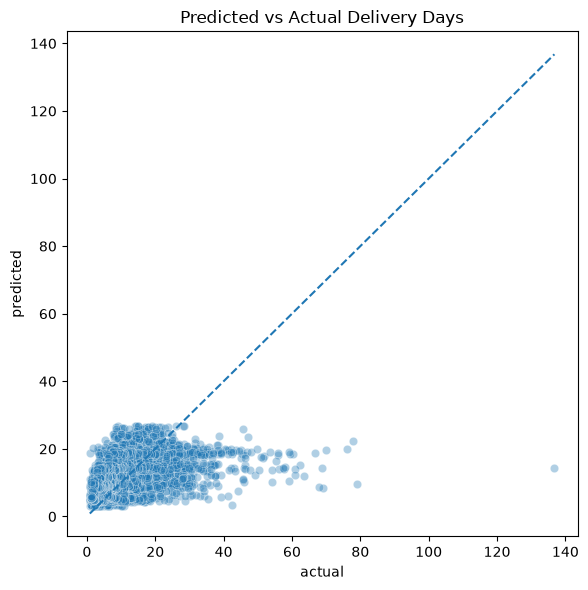

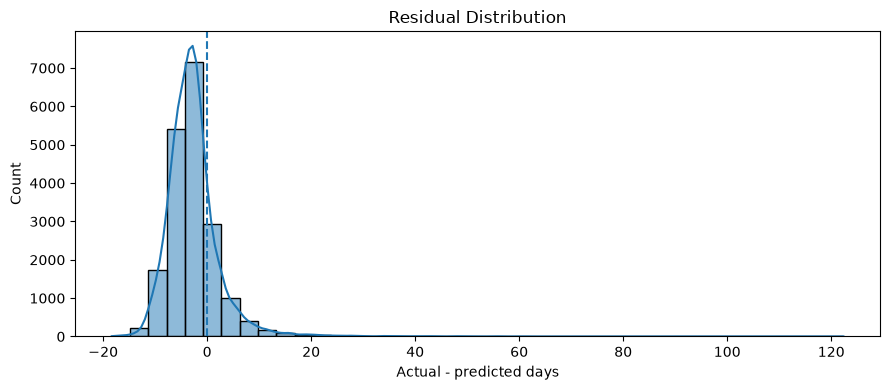

In [10]:
diag=pd.DataFrame({"actual":y_test.to_numpy(),"predicted":pred})
diag["residual"]=diag.actual-diag.predicted
plt.figure(figsize=(6,6)); sns.scatterplot(data=diag,x="actual",y="predicted",alpha=.35)
lo=min(diag.actual.min(),diag.predicted.min()); hi=max(diag.actual.max(),diag.predicted.max())
plt.plot([lo,hi],[lo,hi],"--"); plt.title("Predicted vs Actual Delivery Days")
plt.tight_layout(); plt.savefig(REPORTS/"week4_predicted_vs_actual.png",dpi=160); plt.show()
plt.figure(figsize=(9,4)); sns.histplot(diag.residual,bins=40,kde=True)
plt.axvline(0,ls="--"); plt.title("Residual Distribution"); plt.xlabel("Actual - predicted days")
plt.tight_layout(); plt.savefig(REPORTS/"week4_residuals.png",dpi=160); plt.show()

## 8. Feature importance and optimization strategy

Permutation importance estimates how much the model score worsens when a feature is shuffled. It is useful for prioritizing investigation, but it does not prove causation.

A practical decision-support strategy is to flag orders with predicted delivery duration above a threshold chosen from the training data. Operations can review seller hand-off readiness, allocate capacity during demand peaks, and communicate realistic windows. The intervention should be evaluated against late rate, delivery duration and incremental cost.

In [11]:
importance=permutation_importance(model,X_test,y_test,n_repeats=4,random_state=42,
 scoring="neg_mean_absolute_error",n_jobs=-1)
imp=pd.DataFrame({"feature":features,"importance":importance.importances_mean,
                  "std":importance.importances_std}).sort_values("importance",ascending=False)
display(imp.head(15)); imp.to_csv(REPORTS/"week4_feature_importance.csv",index=False)
threshold=y_train.quantile(.75)
risk=test[["order_id","order_purchase_timestamp"]].copy()
risk["actual_days"]=y_test.to_numpy(); risk["predicted_days"]=pred
risk["high_duration_flag"]=risk.predicted_days>=threshold
risk.to_csv(REPORTS/"week4_predictions_risk_flags.csv",index=False)
print("Training 75th percentile threshold:",round(threshold,2))
print("High-duration flagged share:",round(risk.high_duration_flag.mean()*100,2),"%")

,feature,importance,std
9,customer_state,6.836982e-01,1.426192e-02
7,total_freight,2.172807e-01,6.285013e-03
10,seller_state,2.097162e-01,3.090357e-03
6,total_price,7.774716e-02,7.313013e-04
5,item_count,6.439847e-02,3.368918e-03
8,mean_price,5.700189e-02,1.944188e-03
1,weekday,1.807334e-02,1.634179e-03
4,weekend,2.913044e-03,1.216180e-04
0,month,1.822945e-03,6.380045e-04
2,hour,9.498916e-04,1.503236e-03


Training 75th percentile threshold: 16.97
High-duration flagged share: 12.75 %


## 9. Save model, limitations and reflection

The saved pipeline contains preprocessing and the trained estimator. Keep the metrics and model together. The model applies only to the delivered-order population represented in the training data; it does not directly predict whether an order will be cancelled or never delivered.

Limitations include missing route, carrier, weather, warehouse workload and service-tier features; changes in operations over time; and possible bias from training only on orders with a recorded delivery. Predictions are not causal explanations and should be reviewed by operations staff.

In [12]:
joblib.dump(model,REPORTS/"week4_delivery_duration_model.joblib")
print("Saved model to",REPORTS/"week4_delivery_duration_model.joblib")
print(results.to_string(index=False))
print("Best cross-validation MAE:",round(-search.best_score_,3))

Saved model to C:\Users\SenthamizhSelvan\OneDrive\Desktop\Prakash\YUVA-Data Analyst\reports\week4_delivery_duration_model.joblib
              model  MAE_days  RMSE_days        R2
    Median baseline  4.962445   6.380479 -0.169492
Tuned Random Forest  4.510067   5.908555 -0.002890
Best cross-validation MAE: 6.33


## 10. Reflection and submission checklist

In your Word report, answer: Why is this a regression problem? Which predictors are available at purchase? How did you prevent leakage? Why use a chronological split? Did the model beat the baseline? What do MAE, RMSE and R² indicate? Which features mattered most? What intervention would you pilot, and how would you measure its impact?

Submit this notebook, the report, the metrics CSV, diagnostic plots and (if requested) the saved model.